In [1]:
import pandas as pd
import os
import sys
import json

import seaborn as sns
import numpy as np
import networkx as nx
from pyvis.network import Network

sys.path.append("../functions/")
import networks

In [2]:
from scipy import stats

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [5]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

In [6]:
results_abundance = {}

for file in os.listdir("../output/Venturelli2018/results_steadiercom/results_abundance/"):
    if file.endswith(".tsv") and not file.endswith("_growth.tsv"):
        results_abundance[file[:-4]] = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_abundance/"+file,sep="\t")

results_abundance_df = pd.concat(results_abundance)
results_abundance_df = results_abundance_df.reset_index(drop=True)

In [7]:
results = results_abundance_df.copy()

results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)]
results

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency
0,Faecalibacterium_prausnitzii_A2_165,environment,M_rbflvrd__91__e__93__,8.544633e-01,2.258221,0.622333,PC-,LB_extend,5.317610e-01
1,Faecalibacterium_prausnitzii_A2_165,environment,M_hxan__91__e__93__,8.399863e-01,6.171319,0.052667,PC-,LB_extend,4.423928e-02
2,environment,Bacteroides_uniformis_ATCC_8492,M_malt__91__e__93__,7.474380e-01,2.183604,0.999000,PC-,LB_extend,7.466905e-01
3,Bacteroides_uniformis_ATCC_8492,environment,M_succ__91__e__93__,6.298500e-01,5.426373,1.000000,PC-,LB_extend,6.298500e-01
4,environment,Faecalibacterium_prausnitzii_A2_165,M_ribflv__91__e__93__,5.296394e-01,1.407256,1.000000,PC-,LB_extend,5.296394e-01
...,...,...,...,...,...,...,...,...,...
19833,Desulfovibrio_piger_ATCC_29098,Blautia_hydrogenotrophica_DSM_10507,M_fum__91__e__93__,1.163139e-07,0.000001,0.012876,BO-,LB_extend,1.497604e-09
19834,Collinsella_aerofaciens_ATCC_25986,Eubacterium_rectale_ATCC_33656,M_ac__91__e__93__,1.032038e-07,0.000002,0.002146,BO-,LB_extend,2.214675e-10
19835,Desulfovibrio_piger_ATCC_29098,Bacteroides_thetaiotaomicron_VPI_5482,M_for__91__e__93__,9.954519e-08,0.000002,0.008584,BO-,LB_extend,8.544651e-10
19838,Prevotella_copri_CB7_DSM_18205,Eggerthella_lenta_DSM_2243,M_ac__91__e__93__,8.079365e-08,0.000001,0.066524,BO-,LB_extend,5.374685e-09


In [8]:
abundances_exp_list = []

for file in os.listdir("../data/Venturelli2018/generated/communities_steadiercom/"):
    if file.endswith(".tsv"):
        
        abundance = pd.read_csv("../data/Venturelli2018/generated/communities_steadiercom/"+file,sep="\t",header=None)
        
        abundances_exp_list.append(abundance)
        
        
abundances_exp = pd.concat(abundances_exp_list)

In [9]:
abundances_exp.columns = ["community","member","abundance"]

abundances_exp = abundances_exp.set_index(["community","member"])["abundance"]
abundances_exp = abundances_exp.unstack().T
abundances_exp

community,BH-,BO-,BT-,BU-,BV-,CA-,CH-,DP-,EL-,ER-,FP-,NONE,PC-
member,,,,,,,,,,,,,
Bacteroides_ovatus_ATCC_8483,0.1663,NaN,0.2268,0.3229,0.1354,0.1840,0.1840,0.2149,0.4241,0.1343,0.2537,0.1533,0.1927
Bacteroides_thetaiotaomicron_VPI_5482,0.1714,0.2878,NaN,0.2036,0.2148,0.1644,0.1644,0.1476,0.0933,0.1607,0.2162,0.1452,0.1611
Bacteroides_uniformis_ATCC_8492,0.4236,0.2648,0.4698,NaN,0.3968,0.4358,0.4358,0.2646,0.0962,0.3809,0.3736,0.3649,0.3514
Bacteroides_vulgatus_ATCC_8482,0.0454,0.1536,0.0309,0.0912,NaN,0.0342,0.0342,0.0870,0.0660,0.0415,0.0581,0.0140,0.0348
Blautia_hydrogenotrophica_DSM_10507,NaN,0.0089,0.0222,0.0118,0.0140,0.0091,0.0091,0.0197,0.0002,0.0109,0.0038,0.0100,0.0088
Clostridium_hiranonis_TO_931_DSM_13275,0.0100,0.0175,0.0127,0.0097,0.0118,0.0175,NaN,0.0126,0.0024,0.0106,0.0275,0.0212,0.0122
Collinsella_aerofaciens_ATCC_25986,0.0185,0.0250,0.0325,0.0287,0.0266,NaN,0.0002,0.0179,0.0186,0.0255,0.0297,0.0249,0.0199
Desulfovibrio_piger_ATCC_29098,0.0025,0.0020,0.0006,0.0010,0.0010,0.0007,0.0007,NaN,0.0007,0.0006,0.0013,0.0019,0.0011
Eggerthella_lenta_DSM_2243,0.0210,0.0259,0.0168,0.0239,0.0216,0.0112,0.0112,0.0149,NaN,0.0190,0.0185,0.0168,0.0154


### Out degree (frequency)

In [45]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


In [46]:
import matplotlib.pyplot as plt

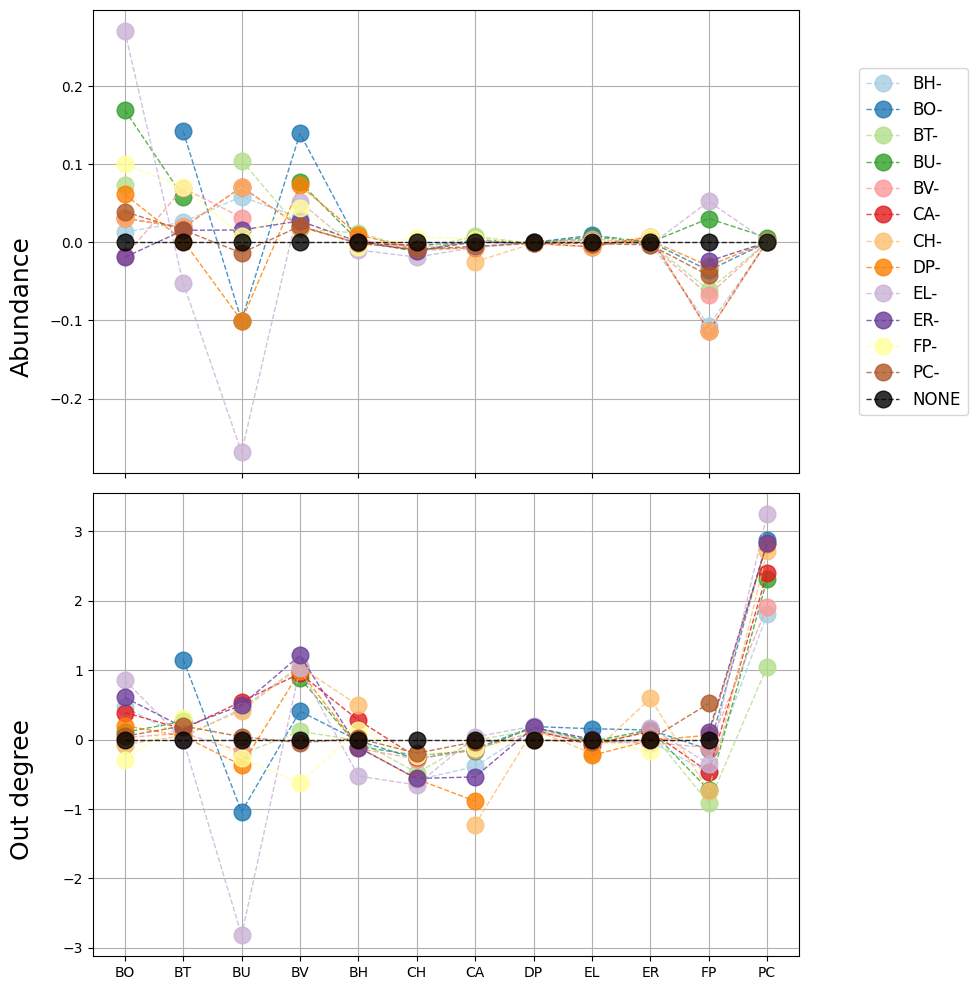

In [47]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("Out degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()
fig.savefig("figures/degree_comm_out.png")


### In degree (frequency)

In [49]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


In [50]:
import matplotlib.pyplot as plt

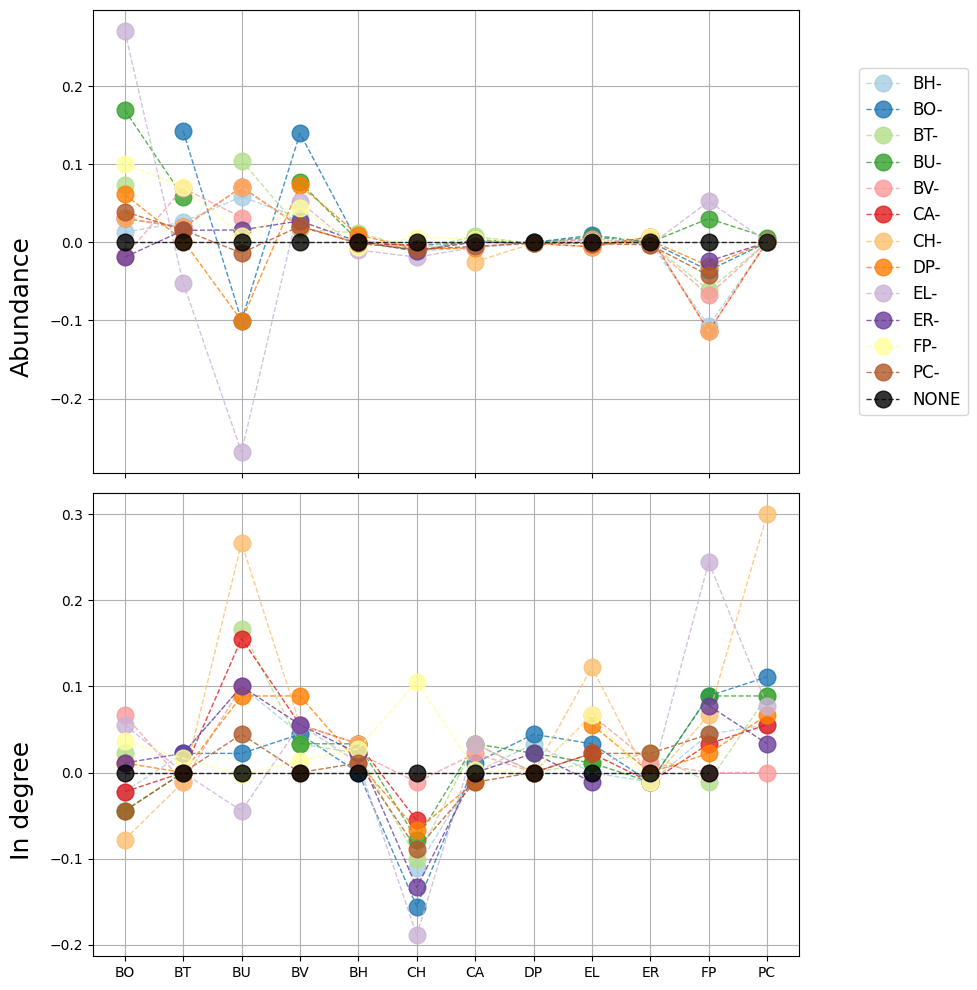

In [62]:
fig,ax = plt.subplots(2,figsize=(25,10))

abundances_exp_none = (abundances_exp.T-abundances_exp["NONE"]).T.drop("NONE",axis=1)

abundances_exp_none.plot(ax=ax[0],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
(abundances_exp["NONE"]-abundances_exp["NONE"]).plot(ax=ax[0],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
labels = ax[0].set_xticklabels("",rotation=90)
title1 = ax[0].set_title("Abundance",x=-.1,y=0.2,fontsize=18,rotation=90)
ax[0].legend(loc='center right', bbox_to_anchor=(1.25, 0.5),fontsize=12)
ax[0].set_xlabel("")

centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(ax=ax[1],marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired",legend=None)
centrality_sorted.T["NONE"].plot(ax=ax[1],color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)
names = centrality_sorted.columns.values
x = [name.split("_")[0][0].upper()+name.split("_")[1][0].upper() for name in names]

ax[1].set_xticks(np.arange(len(x)))
labels = ax[1].set_xticklabels(x)
title2 = ax[1].set_title("In degree",x=-.1,y=0.2,fontsize=18,rotation=90)
plt.tight_layout()


### Out degree (frequency)

In [53]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


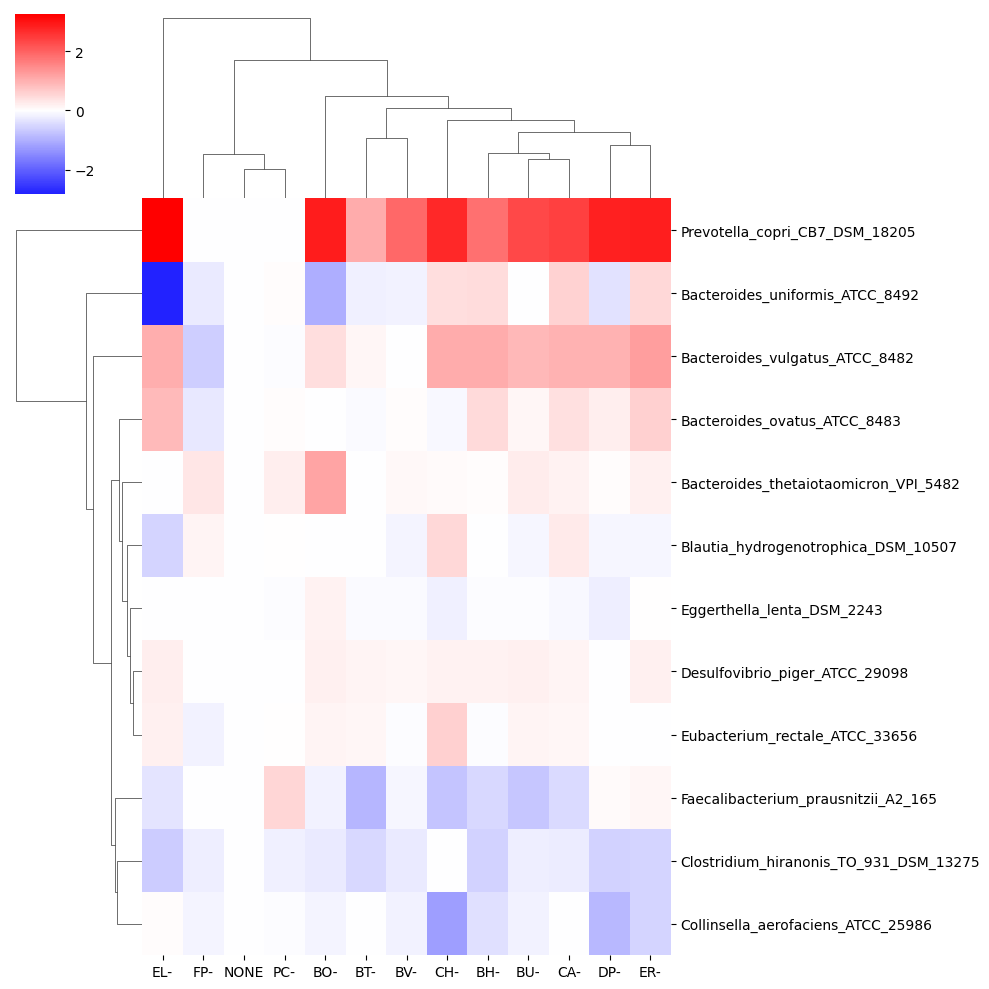

In [54]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### In degree (frequency)

In [56]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


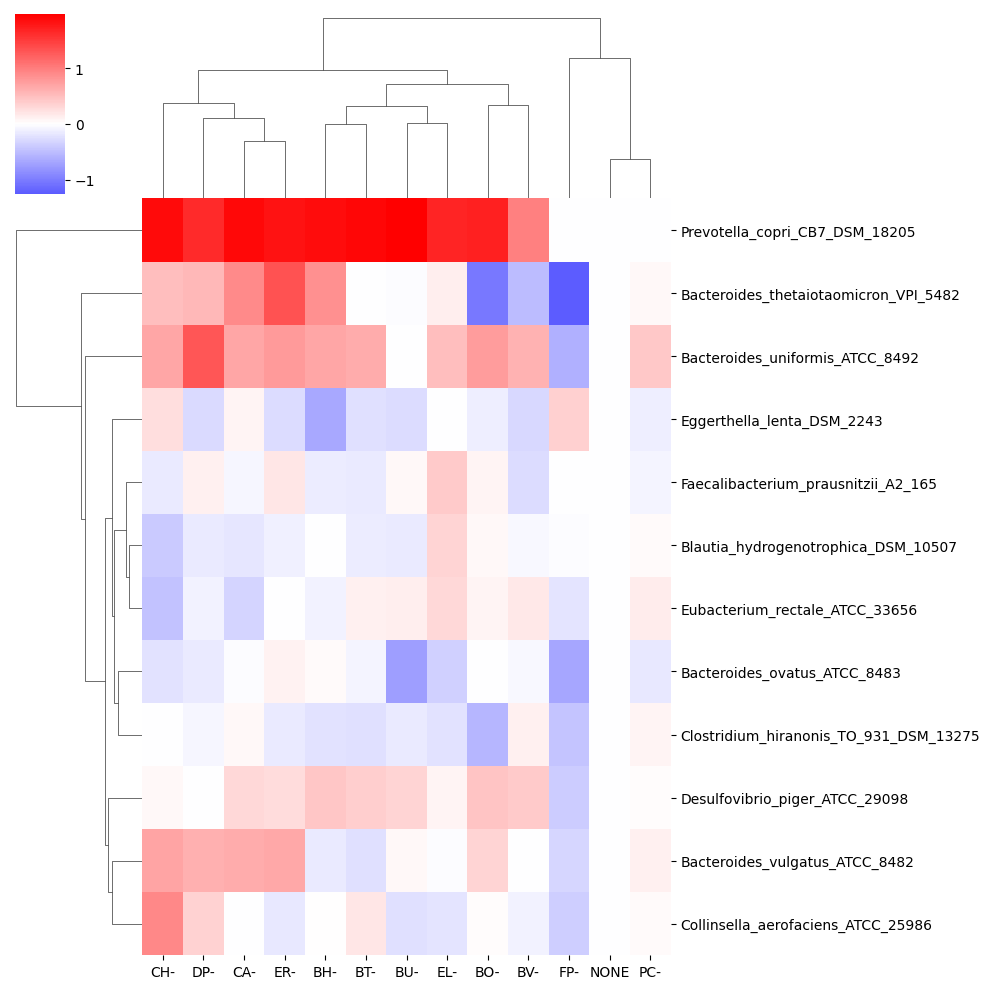

In [57]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### Closeness centrality (frequency)

In [58]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


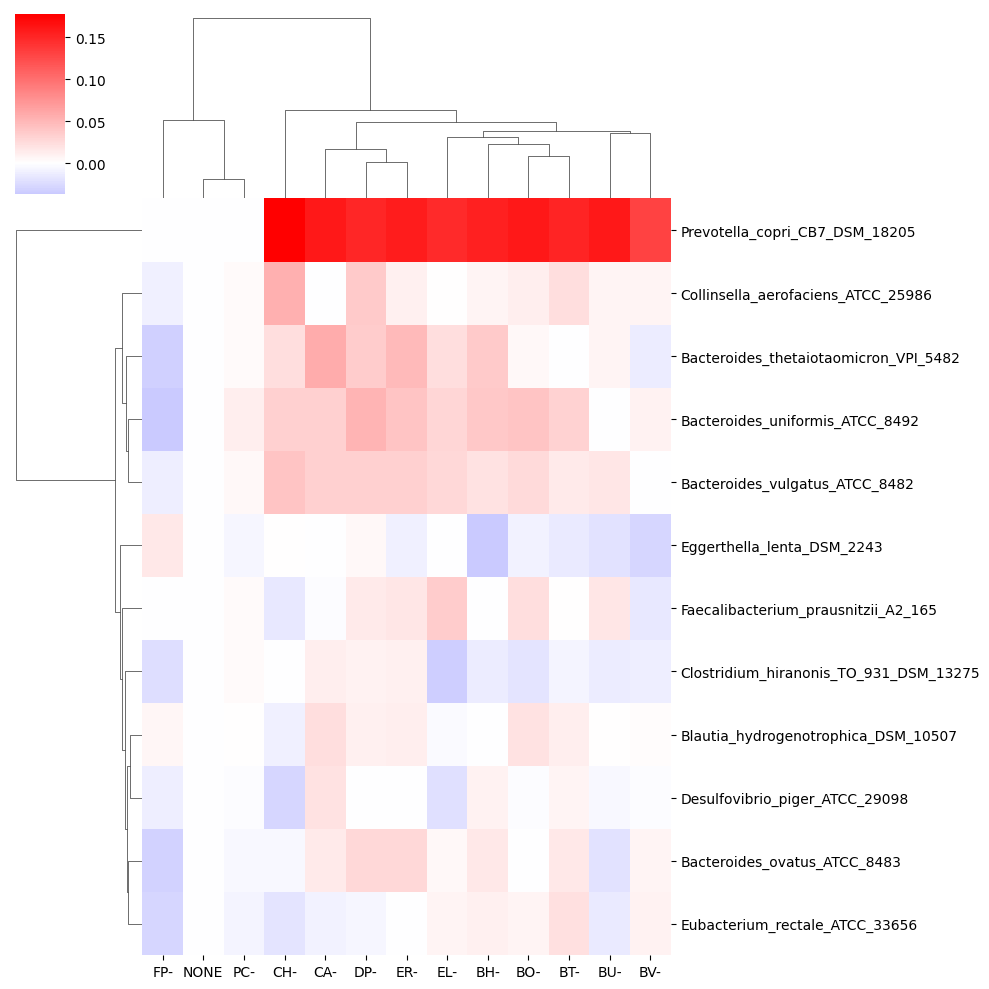

In [59]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)

### Betweeness centrality (frequency)

In [60]:

centrality_metrics_comm= {}

for comm in results.community.unique():
    print(comm)
    results_comm = results[results.community==comm].copy()
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=True,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

centrality = pd.concat(centrality_metrics_comm)["betweeness (1/data)"].unstack()
centrality =centrality.sort_index()


sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

centrality_sorted = centrality_sorted-centrality_sorted.T.loc[:,"NONE"].fillna(0)

PC-
FP-
BT-
CH-
EL-
DP-
BU-
ER-
CA-
BH-
BV-
NONE
BO-


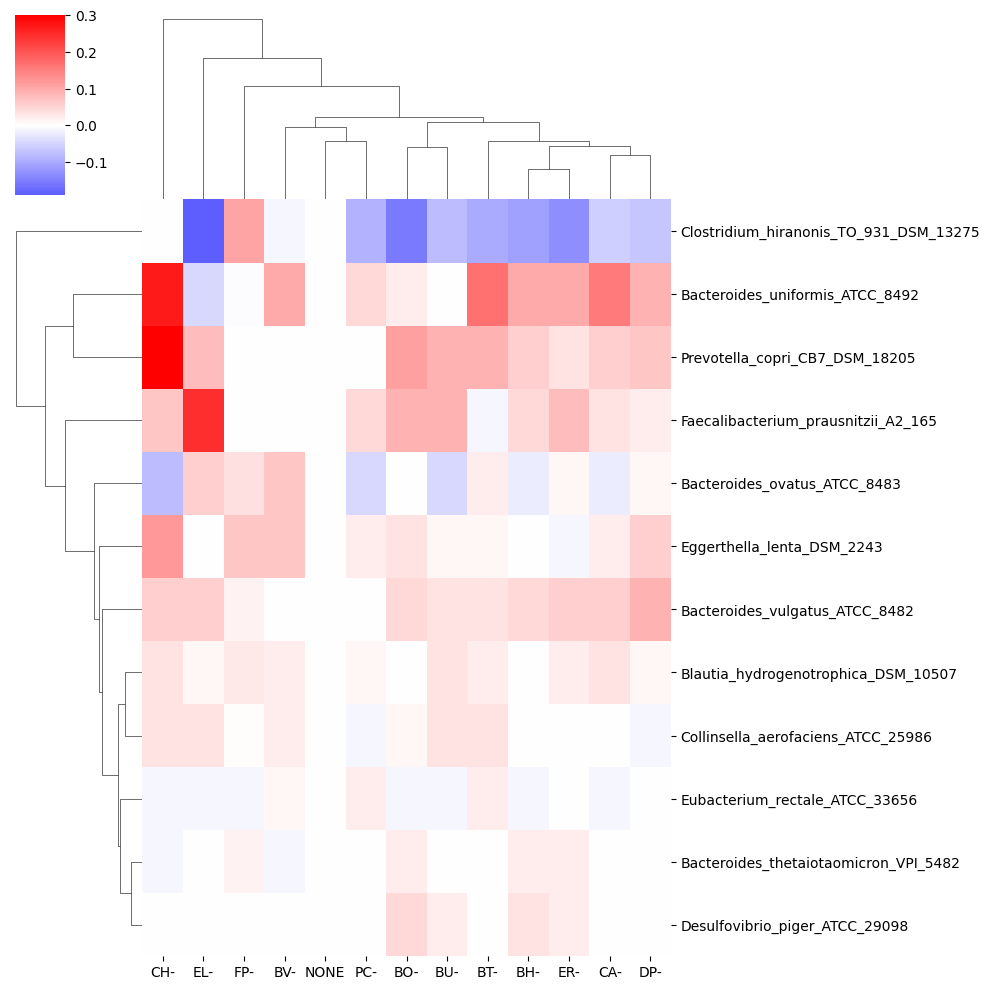

In [61]:
sns.clustermap(centrality_sorted.fillna(0).T,cmap="bwr",center=0)